# Label Propagation digits: sklearn vs Moxie

**Reference example:** `../scikit-learn/examples/semi_supervised/plot_label_propagation_digits.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/semi_supervised/plot_label_propagation_digits.html)).

**Scenario:** `LabelSpreading(gamma=0.25, max_iter=20)` on 340 shuffled digits with 40 labels; the
transduction of the 300 unlabeled points is scored with `classification_report` and a confusion matrix,
and the 10 most uncertain points (entropy of `label_distributions_`) are shown.

**Adaptations:**
- Data is the bundled `load_digits` set, shuffled in Python with the example's `RandomState(2)`, then shared with Mojo.
- `classification_report`, `ConfusionMatrixDisplay` and `scipy.stats.entropy` are reporting steps; they run in Python
  on the transduction and distributions that Moxie learned in Mojo.
- Extra checks beyond the example: `predict`/`predict_proba` on the training points, Float32 features,
  `LabelPropagation` on the same data, `clone` plus refit, and `set_params(alpha=...)` plus refit.

**Determinism:** the reference is deterministic (fixed shuffle seed, closed-form RBF graph, fixed iteration count),
so learned attributes and predictions are compared numerically.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("semi_supervised/plot_label_propagation_digits")

## 1. scikit-learn (Python reference)

In [2]:
import numpy as np
from sklearn import datasets

digits = datasets.load_digits()
rng = np.random.RandomState(2)
indices = np.arange(len(digits.data))
rng.shuffle(indices)

X = digits.data[indices[:340]]
y = digits.target[indices[:340]]
images = digits.images[indices[:340]]

n_total_samples = len(y)
n_labeled_points = 40

indices = np.arange(n_total_samples)

unlabeled_set = indices[n_labeled_points:]

y_train = np.copy(y)
y_train[unlabeled_set] = -1

from sklearn.metrics import classification_report
from sklearn.semi_supervised import LabelSpreading, LabelPropagation

lp_model = LabelSpreading(gamma=0.25, max_iter=20)
lp_model.fit(X, y_train)
predicted_labels = lp_model.transduction_[unlabeled_set]
true_labels = y[unlabeled_set]

print(
    "Label Spreading model: %d labeled & %d unlabeled points (%d total)"
    % (n_labeled_points, n_total_samples - n_labeled_points, n_total_samples)
)
print(classification_report(true_labels, predicted_labels))

from scipy import stats

pred_entropies = stats.distributions.entropy(lp_model.label_distributions_.T)
uncertainty_index = np.argsort(pred_entropies)[-10:]

# Extra reference fits for the checks below.
sk_proba = lp_model.predict_proba(X[:25])
sk_pred = lp_model.predict(X)
sk32 = LabelSpreading(gamma=0.25, max_iter=20).fit(X.astype(np.float32), y_train)
sk_prop = LabelPropagation(gamma=0.25).fit(X, y_train)
sk_alpha = LabelSpreading(gamma=0.25, max_iter=20, alpha=0.5).fit(X, y_train)
print("n_iter_:", lp_model.n_iter_, "float32 n_iter_:", sk32.n_iter_,
      "propagation n_iter_:", sk_prop.n_iter_, "alpha=0.5 n_iter_:", sk_alpha.n_iter_)
nb.share(X=X, y_train=y_train)

Label Spreading model: 40 labeled & 300 unlabeled points (340 total)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       0.82      1.00      0.90        37
           2       1.00      0.86      0.92        28
           3       1.00      0.80      0.89        35
           4       0.92      1.00      0.96        24
           5       0.74      0.94      0.83        34
           6       0.89      0.96      0.92        25
           7       0.94      0.89      0.91        35
           8       1.00      0.68      0.81        31
           9       0.81      0.88      0.84        24

    accuracy                           0.90       300
   macro avg       0.91      0.90      0.90       300
weighted avg       0.91      0.90      0.90       300

n_iter_: 7 float32 n_iter_: 7 propagation n_iter_: 2 alpha=0.5 n_iter_: 15


## 2. Moxie (native Mojo)

The same fit through `moxie.semi_supervised`. Integer `-1` marks unlabeled samples, as in sklearn.

In [3]:
%%mojo digits_spreading
from moxie.base import clone
from moxie.semi_supervised import LabelSpreading, LabelPropagation
from moxie_nb_io import load, load_ints, save, save_ints
from numojo import NDArray, Shape, Item


def head[d: DType](X: NDArray[d], n: Int) raises -> NDArray[d]:
    var out = NDArray[d](Shape(n, X.shape[1]))
    for i in range(n):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(i, j)]
    return out^


def main() raises:
    var X = load("X")
    var y_train = load_ints("y_train")
    var lp_model = LabelSpreading(gamma=0.25, max_iter=20)
    _ = lp_model.fit(X, y_train)
    save("label_distributions", lp_model.label_distributions_)
    save_ints("transduction", lp_model.transduction_)
    save_ints("classes", lp_model.classes_)
    save_ints("n_iter", [lp_model.n_iter_, lp_model.n_features_in_])
    save("proba", lp_model.predict_proba(head(X, 25)))
    save_ints("pred", lp_model.predict(X))

    var X32 = X.astype[DType.float32]()
    var model32 = LabelSpreading[DType.float32](gamma=0.25, max_iter=20)
    _ = model32.fit(X32, y_train)
    save("dist32", model32.label_distributions_)
    save_ints("trans32", model32.transduction_)
    save_ints("n_iter32", [model32.n_iter_])

    var prop = LabelPropagation(gamma=0.25)
    _ = prop.fit(X, y_train)
    save("prop_dist", prop.label_distributions_)
    save_ints("prop_trans", prop.transduction_)
    save_ints("prop_n_iter", [prop.n_iter_])

    # clone carries configuration only; the refit must reproduce the original.
    var fresh = clone(lp_model)
    print("clone fitted before fit:", fresh.__sklearn_is_fitted__())
    _ = fresh.fit(X, y_train)
    save("clone_dist", fresh.label_distributions_)
    # set_params then refit replaces the learned state.
    _ = fresh.set_params(alpha=0.5).fit(X, y_train)
    save("alpha_dist", fresh.label_distributions_)
    save_ints("alpha_n_iter", [fresh.n_iter_])

clone fitted before fit: False


## 3. Side by side and parity

Moxie transduction report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       0.82      1.00      0.90        37
           2       1.00      0.86      0.92        28
           3       1.00      0.80      0.89        35
           4       0.92      1.00      0.96        24
           5       0.74      0.94      0.83        34
           6       0.89      0.96      0.92        25
           7       0.94      0.89      0.91        35
           8       1.00      0.68      0.81        31
           9       0.81      0.88      0.84        24

    accuracy                           0.90       300
   macro avg       0.91      0.90      0.90       300
weighted avg       0.91      0.90      0.90       300



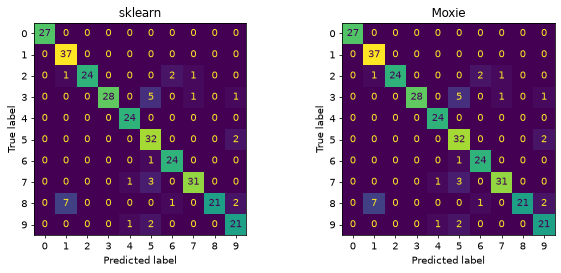

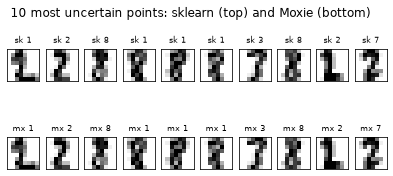

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

mx = nb.results["digits_spreading"]
mx_pred_unlabeled = mx["transduction"][unlabeled_set]
print("Moxie transduction report:")
print(classification_report(true_labels, mx_pred_unlabeled))
mx_entropies = stats.distributions.entropy(mx["label_distributions"].T)
mx_uncertainty = np.argsort(mx_entropies)[-10:]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=70)
ConfusionMatrixDisplay.from_predictions(true_labels, predicted_labels, labels=lp_model.classes_,
                                        ax=axes[0], colorbar=False)
axes[0].set_title("sklearn")
ConfusionMatrixDisplay.from_predictions(true_labels, mx_pred_unlabeled, labels=mx["classes"],
                                        ax=axes[1], colorbar=False)
axes[1].set_title("Moxie")
plt.tight_layout(); plt.show()

f = plt.figure(figsize=(7, 3), dpi=70)
for index, image_index in enumerate(mx_uncertainty):
    sub = f.add_subplot(2, 10, index + 1)
    sub.imshow(images[uncertainty_index[index]], cmap=plt.cm.gray_r); sub.set_xticks([]); sub.set_yticks([])
    sub.set_title("sk %i" % lp_model.transduction_[uncertainty_index[index]], fontsize=8)
    sub = f.add_subplot(2, 10, index + 11)
    sub.imshow(images[image_index], cmap=plt.cm.gray_r); sub.set_xticks([]); sub.set_yticks([])
    sub.set_title("mx %i" % mx["transduction"][image_index], fontsize=8)
f.suptitle("10 most uncertain points: sklearn (top) and Moxie (bottom)")
plt.show()
moxie_nb.side_by_side(sklearn=lp_model.label_distributions_[:5], moxie=mx["label_distributions"][:5])

In [5]:
F64 = "Float64 graph and diffusion; NumPy pairwise sums and BLAS GEMM vs native reduction order"
F32 = ("sklearn builds the Float32 RBF graph and Laplacian in float32, Moxie rounds the RBF values to float32 "
       "but normalises in Float64; differences are float32 rounding (~1e-7 relative) amplified over 20 steps")
nb.compare("classes_", lp_model.classes_, mx["classes"], exact=True)
nb.compare("n_iter_ / n_features_in_", [lp_model.n_iter_, lp_model.n_features_in_], mx["n_iter"], exact=True)
nb.compare("label_distributions_", lp_model.label_distributions_, mx["label_distributions"], rtol=1e-9, atol=1e-12, reason=F64)
nb.compare("transduction_", lp_model.transduction_, mx["transduction"], exact=True)
nb.compare("classification report (unlabeled accuracy)", (predicted_labels == true_labels).mean(),
           (mx_pred_unlabeled == true_labels).mean(), exact=True)
nb.compare("entropy", pred_entropies, mx_entropies, rtol=1e-8, atol=1e-12, reason=F64)
nb.compare("top-10 uncertain indices", uncertainty_index, mx_uncertainty, exact=True)
nb.compare("predict_proba(X[:25])", sk_proba, mx["proba"], rtol=1e-9, atol=1e-12, reason=F64)
nb.compare("predict(X)", sk_pred, mx["pred"], exact=True)
nb.compare("Float32 n_iter_", sk32.n_iter_, mx["n_iter32"][0], exact=True)
nb.compare("Float32 label_distributions_", sk32.label_distributions_, mx["dist32"], rtol=0, atol=3e-5, reason=F32)
nb.compare("Float32 transduction_", sk32.transduction_, mx["trans32"], exact=True)
nb.compare("LabelPropagation n_iter_", sk_prop.n_iter_, mx["prop_n_iter"][0], exact=True)
nb.compare("LabelPropagation label_distributions_", sk_prop.label_distributions_, mx["prop_dist"], rtol=1e-8, atol=1e-11,
           reason=F64 + "; up to 1000 hard-clamped iterations accumulate rounding")
nb.compare("LabelPropagation transduction_", sk_prop.transduction_, mx["prop_trans"], exact=True)
nb.compare("clone + refit reproduces fit", mx["label_distributions"], mx["clone_dist"], exact=True)
nb.compare("set_params(alpha=0.5) refit n_iter_", sk_alpha.n_iter_, mx["alpha_n_iter"][0], exact=True)
nb.compare("set_params(alpha=0.5) refit label_distributions_", sk_alpha.label_distributions_, mx["alpha_dist"],
           rtol=1e-9, atol=1e-12, reason=F64)
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
classes_,PASS,"(10,)","(10,)",,,exact,0 mismatches,
n_iter_ / n_features_in_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
label_distributions_,PASS,"(340, 10)","(340, 10)",1.11e-16,1.72e-15,"rtol=1e-09, atol=1e-12",,Float64 graph and diffusion; NumPy pairwise sums and BLAS GEMM vs native reduction order
transduction_,PASS,"(340,)","(340,)",,,exact,0 mismatches,
classification report (unlabeled accuracy),PASS,(),(),,,exact,0 mismatches,
entropy,PASS,"(340,)","(340,)",1.11e-16,1.14e-11,"rtol=1e-08, atol=1e-12",,Float64 graph and diffusion; NumPy pairwise sums and BLAS GEMM vs native reduction order
top-10 uncertain indices,PASS,"(10,)","(10,)",,,exact,0 mismatches,
predict_proba(X[:25]),PASS,"(25, 10)","(25, 10)",1.48e-66,8.93e-16,"rtol=1e-09, atol=1e-12",,Float64 graph and diffusion; NumPy pairwise sums and BLAS GEMM vs native reduction order
predict(X),PASS,"(340,)","(340,)",,,exact,0 mismatches,
Float32 n_iter_,PASS,(),(),,,exact,0 mismatches,
